|<h2>Book:</h2>|<h1><a href="https://open.substack.com/pub/mikexcohen/p/llm-breakdown-16-tokenization-words" target="_blank">50 ML projects to understand LLMs</a></h1>|
|-|:-:|
|<h2>Project:</h2>|<h1><b>[11] Graphs of cosine similarity</b></h1>|
|<h2>Author:<h2>|<h1>Mike X Cohen, <a href="https://sincxpress.com" target="_blank">sincxpress.com</a></h1>|

<br>

<i>Using the code without reading the book may lead to confusion or errors.</i>

In [1]:
import numpy as np
import matplotlib.pyplot as plt

In [2]:
### matplotlib adjustments (commented lines are for dark mode)

# svg plots (higher-res)
import matplotlib_inline.backend_inline
matplotlib_inline.backend_inline.set_matplotlib_formats('svg')

plt.rcParams.update({
    # 'figure.facecolor': '#282a2c',
    # 'figure.edgecolor': '#282a2c',
    # 'axes.facecolor':   '#282a2c',
    # 'axes.edgecolor':   '#DDE2F4',
    # 'axes.labelcolor':  '#DDE2F4',
    # 'xtick.color':      '#DDE2F4',
    # 'ytick.color':      '#DDE2F4',
    # 'text.color':       '#DDE2F4',
    'axes.spines.right': False,
    'axes.spines.top':   False,
    'axes.titleweight': 'bold',
    'axes.labelweight': 'bold',
    'savefig.dpi':300,
})

# **Part 1: Tokens, embeddings, and cosine similarity**

In [3]:
from transformers import BertTokenizer, BertModel

# load BERT tokenizer and model
tokenizer = BertTokenizer.from_pretrained('bert-large-uncased')
model = BertModel.from_pretrained('bert-large-uncased')

embeddings = model.embeddings.word_embeddings.weight.detach().numpy()

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

c:\Users\daler\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\huggingface_hub\file_download.py:143: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\daler\.cache\huggingface\hub\models--bert-large-uncased. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

config.json:   0%|          | 0.00/571 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.34GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/391 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: bert-large-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


In [20]:
text = 'As Gregor Samsa awoke one morning from uneasy dreams he found himself transformed in his bed into a gigantic bug'

tokens = tokenizer.encode(text,add_special_tokens=False)

print(f'There are {len(tokens)} tokens in the text, {len(set(tokens))} of which are unique.\n')

for t in tokens:
  print(f'Token index {t:5} is "{tokenizer.decode(t)}"')

There are 21 tokens in the text, 21 of which are unique.

Token index  2004 is "as"
Token index 16973 is "gregor"
Token index  3520 is "sam"
Token index  3736 is "##sa"
Token index 19179 is "awoke"
Token index  2028 is "one"
Token index  2851 is "morning"
Token index  2013 is "from"
Token index 15491 is "uneasy"
Token index  5544 is "dreams"
Token index  2002 is "he"
Token index  2179 is "found"
Token index  2370 is "himself"
Token index  8590 is "transformed"
Token index  1999 is "in"
Token index  2010 is "his"
Token index  2793 is "bed"
Token index  2046 is "into"
Token index  1037 is "a"
Token index 20193 is "gigantic"
Token index 11829 is "bug"


In [21]:
E = embeddings[tokens,:]

# normalize each vector to its norm (unit length)
E_norm = E / np.linalg.norm(E,axis=1,keepdims=True)

# cosine similarity matrix
csM = E_norm @ E_norm.T

# get a vector of all unique matrix elements
uniqueCS = csM[np.nonzero(np.triu(csM,1))]

# here's the threshold!
thresh = np.median(uniqueCS) + np.std(uniqueCS)

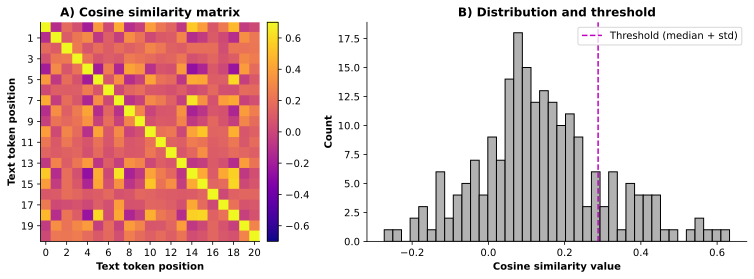

In [22]:
# visualize
fig,axs = plt.subplots(1,2,figsize=(12,4))

h = axs[0].imshow(csM,vmin=-.7,vmax=.7,cmap='plasma')
axs[0].set(xlabel='Text token position',ylabel='Text token position',
           xticks=range(0,len(tokens),2),yticks=range(1,len(tokens),2),
           title='A) Cosine similarity matrix')
fig.colorbar(h,ax=axs[0],fraction=.046,pad=.02)

axs[1].hist(uniqueCS,bins=40,color=[.7,.7,.7],edgecolor='k')
axs[1].axvline(thresh,linestyle='--',color='m',label='Threshold (median + std)')

axs[1].legend()
axs[1].set(xlabel='Cosine similarity value',ylabel='Count',title='B) Distribution and threshold')

plt.tight_layout()
plt.savefig('ch3_proj11_part1.png')
plt.show()

# **Part 2: The network similarity graph**

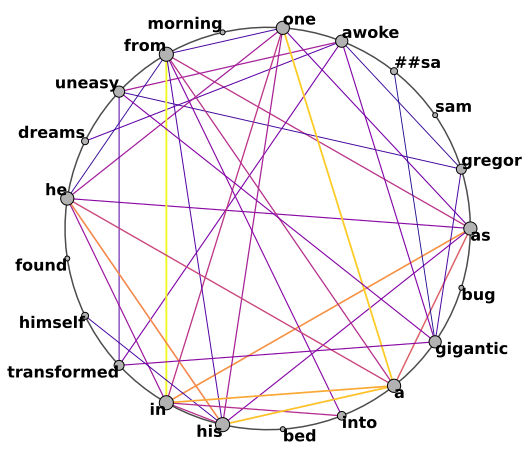

In [23]:
# values for theta
N = len(tokens)
th = np.linspace(0,2*np.pi-2*np.pi/N,N)

maxcs = np.sort(csM[csM<.99])[-1]

# create a figure
plt.figure(figsize=(8,8))

thHighres = np.linspace(0,2*np.pi,100)
plt.plot(np.cos(thHighres),np.sin(thHighres),color=[.3,.3,.3])

# loop over tokens
for i in range(N):

  # determine dot (marker) size
  dotsize = 5 * np.sqrt((csM[i]>thresh).sum())

  # plot the dot
  plt.plot(np.cos(th[i]),np.sin(th[i]),'ko',markerfacecolor=[.7,.7,.7],markersize=dotsize)

  # draw text at the tokens
  plt.text(np.cos(th[i]),np.sin(th[i]),tokenizer.decode([tokens[i]]),
           ha=['right','left'][int(np.cos(th[i])>0)], # pick a side based on cosine sign
           va=['top','bottom'][int(np.sin(th[i])>0)], # pick a vertical orientation from sine
           fontweight='bold',fontsize=16)

  # loop over all the other tokens
  for j in range(i+1,N):

    # only draw a line if similarity exceeds the threshold
    if csM[i,j]>thresh:

      # color corresponding to cossim strength
      cidx = (csM[i,j]-thresh) / (maxcs-thresh)
      color = plt.cm.plasma(cidx)

      # draw it!
      x_vals = [ np.cos(th[i]),np.cos(th[j]) ]
      y_vals = [ np.sin(th[i]),np.sin(th[j]) ]
      plt.plot(x_vals,y_vals,zorder=-10,color=color,linewidth=3*csM[i,j])

plt.axis('off')

plt.savefig('ch3_proj11_part2.png')
plt.show()

In [30]:
import pandas as pd

connection_rows = []

N = len(tokens)

for i in range(N):
    for j in range(i + 1, N):

        similarity = csM[i, j].item()

        if similarity > thresh:

            connection_rows.append({
                'Token 1': repr(
                    tokenizer.decode([tokens[i]])
                ),
                'Token 2': repr(
                    tokenizer.decode([tokens[j]])
                ),
                'Token index 1': tokens[i],
                'Token index 2': tokens[j],
                'Cosine similarity': similarity
            })

word_connections = (
    pd.DataFrame(connection_rows)
    .sort_values(
        'Cosine similarity',
        ascending=False
    )
    .reset_index(drop=True)
)

display(
    word_connections.style
    .background_gradient(
        subset=['Cosine similarity'],
        cmap='plasma'
    )
    .format({
        'Cosine similarity': '{:.4f}'
    })
)

IndexError: index 21 is out of bounds for axis 1 with size 21

In [24]:
node_rows = []

for i in range(N):

    connected_positions = []

    for j in range(N):

        if i != j and csM[i, j].item() > thresh:
            connected_positions.append(j)

    connected_tokens = [
        repr(tokenizer.decode([tokens[j]]))
        for j in connected_positions
    ]

    connected_similarities = [
        csM[i, j].item()
        for j in connected_positions
    ]

    node_rows.append({
        'Token': repr(tokenizer.decode([tokens[i]])),
        'Token index': tokens[i],
        'Number of connections': len(connected_positions),
        'Connected tokens': connected_tokens,
        'Similarities': [
            round(value, 4)
            for value in connected_similarities
        ]
    })

node_connections = (
    pd.DataFrame(node_rows)
    .sort_values(
        'Number of connections',
        ascending=False
    )
    .reset_index(drop=True)
)

display(node_connections)

,Token,Token index,Number of connections,Connected tokens,Similarities
0,'from',2013,7,"['as', 'one', 'he', 'in', 'his', 'into', 'a']","[0.4377, 0.3263, 0.3109, 0.6326, 0.337, 0.3839..."
1,'in',1999,7,"['as', 'one', 'from', 'he', 'his', 'into', 'a']","[0.5433, 0.4399, 0.6326, 0.4029, 0.4322, 0.428..."
2,'his',2010,7,"['as', 'one', 'from', 'he', 'himself', 'in', 'a']","[0.3813, 0.4161, 0.337, 0.5322, 0.3239, 0.4322..."
3,'one',2028,6,"['as', 'from', 'he', 'in', 'his', 'a']","[0.3682, 0.3263, 0.4101, 0.4399, 0.4161, 0.5955]"
4,'as',2004,6,"['one', 'from', 'he', 'in', 'his', 'a']","[0.3682, 0.4377, 0.3874, 0.5433, 0.3813, 0.4891]"
5,'he',2002,6,"['as', 'one', 'from', 'in', 'his', 'a']","[0.3874, 0.4101, 0.3109, 0.4029, 0.5322, 0.4575]"
6,'a',1037,6,"['as', 'one', 'from', 'he', 'in', 'his']","[0.4891, 0.5955, 0.4309, 0.4575, 0.5642, 0.5871]"
7,'gigantic',20193,5,"['gregor', '##sa', 'awoke', 'uneasy', 'transfo...","[0.3301, 0.2968, 0.3793, 0.3826, 0.3857]"
8,'awoke',19179,5,"['gregor', 'uneasy', 'dreams', 'transformed', ...","[0.311, 0.4128, 0.3462, 0.3729, 0.3793]"
9,'uneasy',15491,4,"['gregor', 'awoke', 'transformed', 'gigantic']","[0.3222, 0.4128, 0.3363, 0.3826]"


In [ ]:
nearest_rows = []

for i in range(N):

    candidate_positions = [
        j for j in range(N)
        if j != i and csM[i, j].item() > thresh
    ]

    if candidate_positions:

        nearest_position = max(
            candidate_positions,
            key=lambda j: csM[i, j].item()
        )

        nearest_token = repr(
            tokenizer.decode([tokens[nearest_position]])
        )

        nearest_similarity = csM[
            i, nearest_position
        ].item()

    else:

        nearest_token = None
        nearest_similarity = np.nan

    nearest_rows.append({
        'Token': repr(tokenizer.decode([tokens[i]])),
        'Most similar connected token': nearest_token,
        'Cosine similarity': nearest_similarity
    })

nearest_words = (
    pd.DataFrame(nearest_rows)
    .sort_values(
        'Cosine similarity',
        ascending=False,
        na_position='last'
    )
    .reset_index(drop=True)
)

display(
    nearest_words.style
    .background_gradient(
        subset=['Cosine similarity'],
        cmap='plasma'
    )
    .format({
        'Cosine similarity': '{:.4f}'
    })
)

,Token,Most similar connected token,Cosine similarity
0,'from','in',0.6326
1,'in','from',0.6326
2,'a','one',0.5955
3,'one','a',0.5955
4,'his','a',0.5871
5,'as','in',0.5433
6,'he','his',0.5322
7,'into','in',0.4282
8,'awoke','uneasy',0.4128
9,'uneasy','awoke',0.4128


In [42]:
import re
import pandas as pd

text = (
    'O rei entrou no castelo e a rainha saiu do palácio, '
    'enquanto o homem abriu a porta e a mulher fechou a janela'
)

# Separar palavras e pontuação
all_words = re.findall(
    r'\w+|[^\w\s]',
    text,
    flags=re.UNICODE
)

# Remover palavras repetidas, preservando a ordem
words = list(dict.fromkeys(all_words))

word_tokenization = []

for word in words:

    # Tokens textuais, como "caste" e "##lo"
    token_pieces = tokenizer.tokenize(word)

    # Índices correspondentes no vocabulário
    token_indices = tokenizer.convert_tokens_to_ids(
        token_pieces
    )

    word_tokenization.append({
        'Word': word,
        'Number of tokens': len(token_pieces),
        'Tokens': token_pieces,
        'Token indices': token_indices
    })

word_tokenization_table = pd.DataFrame(
    word_tokenization
)

display(word_tokenization_table)

,Word,Number of tokens,Tokens,Token indices
0,O,1,[o],[1051]
1,rei,1,[rei],[24964]
2,entrou,3,"[en, ##tro, ##u]","[4372, 13181, 2226]"
3,no,1,[no],[2053]
4,castelo,2,"[caste, ##lo]","[14542, 4135]"
5,e,1,[e],[1041]
6,a,1,[a],[1037]
7,rainha,2,"[rain, ##ha]","[4542, 3270]"
8,saiu,2,"[sai, ##u]","[18952, 2226]"
9,do,1,[do],[2079]


In [41]:
import pandas as pd

connection_rows = []

N = len(tokens)

for i in range(N):
    for j in range(i + 1, N):

        similarity = csM[i, j].item()

        if similarity > thresh:

            connection_rows.append({
                'Token 1': repr(
                    tokenizer.decode([tokens[i]])
                ),
                'Token 2': repr(
                    tokenizer.decode([tokens[j]])
                ),
                'Token index 1': tokens[i],
                'Token index 2': tokens[j],
                'Cosine similarity': similarity
            })

word_connections = (
    pd.DataFrame(connection_rows)
    .sort_values(
        'Cosine similarity',
        ascending=False
    )
    .reset_index(drop=True)
)

display(
    word_connections.style
    .background_gradient(
        subset=['Cosine similarity'],
        cmap='plasma'
    )
    .format({
        'Cosine similarity': '{:.4f}'
    })
)
node_rows = []

for i in range(N):

    connected_positions = []

    for j in range(N):

        if i != j and csM[i, j].item() > thresh:
            connected_positions.append(j)

    connected_tokens = [
        repr(tokenizer.decode([tokens[j]]))
        for j in connected_positions
    ]

    connected_similarities = [
        csM[i, j].item()
        for j in connected_positions
    ]

    node_rows.append({
        'Token': repr(tokenizer.decode([tokens[i]])),
        'Token index': tokens[i],
        'Number of connections': len(connected_positions),
        'Connected tokens': connected_tokens,
        'Similarities': [
            round(value, 4)
            for value in connected_similarities
        ]
    })

node_connections = (
    pd.DataFrame(node_rows)
    .sort_values(
        'Number of connections',
        ascending=False
    )
    .reset_index(drop=True)
)

display(node_connections)
nearest_rows = []

for i in range(N):

    candidate_positions = [
        j for j in range(N)
        if j != i and csM[i, j].item() > thresh
    ]

    if candidate_positions:

        nearest_position = max(
            candidate_positions,
            key=lambda j: csM[i, j].item()
        )

        nearest_token = repr(
            tokenizer.decode([tokens[nearest_position]])
        )

        nearest_similarity = csM[
            i, nearest_position
        ].item()

    else:

        nearest_token = None
        nearest_similarity = np.nan

    nearest_rows.append({
        'Token': repr(tokenizer.decode([tokens[i]])),
        'Most similar connected token': nearest_token,
        'Cosine similarity': nearest_similarity
    })

nearest_words = (
    pd.DataFrame(nearest_rows)
    .sort_values(
        'Cosine similarity',
        ascending=False,
        na_position='last'
    )
    .reset_index(drop=True)
)

display(
    nearest_words.style
    .background_gradient(
        subset=['Cosine similarity'],
        cmap='plasma'
    )
    .format({
        'Cosine similarity': '{:.4f}'
    })
)

,Token 1,Token 2,Token index 1,Token index 2,Cosine similarity
0,'a',"','",1037,1010,0.6041
1,'##u','##a',2226,2050,0.5256
2,'##lo','##la',4135,2721,0.5185
3,'##a','##l',2050,2140,0.5077
4,"','",'##a',1010,2050,0.4706
5,'##m','##l',2213,2140,0.4597
6,'##a','##la',2050,2721,0.4532
7,'##m','##a',2213,2050,0.4485
8,'##ha','##la',3270,2721,0.4484
9,'a','##a',1037,2050,0.4427


,Token,Token index,Number of connections,Connected tokens,Similarities
0,'##a',2050,11,"['o', '##u', '##lo', 'e', 'a', '##ha', ',', '#...","[0.3067, 0.5256, 0.3257, 0.3436, 0.4427, 0.408..."
1,'##lo',4135,10,"['o', 'rei', '##tro', '##u', '##nto', '##ri', ...","[0.325, 0.3032, 0.3508, 0.3173, 0.3549, 0.3364..."
2,'##ri',3089,10,"['rei', '##u', '##lo', '##ha', 'sai', '##m', '...","[0.3366, 0.3699, 0.3364, 0.3509, 0.3261, 0.335..."
3,'##u',2226,9,"['o', '##lo', '##ha', 'sai', '##m', '##ri', '#...","[0.3188, 0.3173, 0.3648, 0.3158, 0.4131, 0.369..."
4,'##cho',9905,9,"['rei', '##tro', '##lo', '##ha', 'sai', 'pal',...","[0.369, 0.3664, 0.3577, 0.3288, 0.3089, 0.302,..."
5,'##l',2140,9,"['##u', '##lo', 'a', '##ha', ',', '##m', '##ri...","[0.4229, 0.3785, 0.3082, 0.3419, 0.3668, 0.459..."
6,'##ha',3270,9,"['##u', '##qua', '##m', '##ri', '##a', '##l', ...","[0.3648, 0.3193, 0.3045, 0.3509, 0.4082, 0.341..."
7,'rei',24964,8,"['##tro', '##lo', 'sai', '##qua', '##nto', '##...","[0.3199, 0.3032, 0.3525, 0.329, 0.3165, 0.3366..."
8,'##nto',13663,7,"['rei', '##tro', '##lo', 'sai', '##acio', '##q...","[0.3165, 0.3623, 0.3549, 0.3193, 0.3853, 0.358..."
9,'##la',2721,7,"['##u', '##lo', '##ha', '##m', '##ri', '##a', ...","[0.3746, 0.5185, 0.4484, 0.3396, 0.3327, 0.453..."


,Token,Most similar connected token,Cosine similarity
0,'a',"','",0.6041
1,"','",'a',0.6041
2,'##u','##a',0.5256
3,'##a','##u',0.5256
4,'##lo','##la',0.5185
5,'##la','##lo',0.5185
6,'##l','##a',0.5077
7,'##m','##l',0.4597
8,'##ha','##la',0.4484
9,'no','a',0.4389


# **Part 3: Graphing number networks**

In [8]:
# tokenize and confirm single-token encoding
text = [str(i) for i in range(10)] + [str(i*10) for i in range(1,11)]
tokens = tokenizer.encode(text,add_special_tokens=False)
tokens = [t[0] for t in tokens] # list from list of lists

for t in tokens:
  print(f'{t} is "{tokenizer.decode(t)}"')

1014 is "0"
1015 is "1"
1016 is "2"
1017 is "3"
1018 is "4"
1019 is "5"
1020 is "6"
1021 is "7"
1022 is "8"
1023 is "9"
2184 is "10"
2322 is "20"
2382 is "30"
2871 is "40"
2753 is "50"
3438 is "60"
3963 is "70"
3770 is "80"
3938 is "90"
2531 is "100"


In [9]:
# cosine similarity matrix
E = embeddings[tokens,:]
E_norm = E / np.linalg.norm(E,axis=1,keepdims=True)
csM = E_norm @ E_norm.T

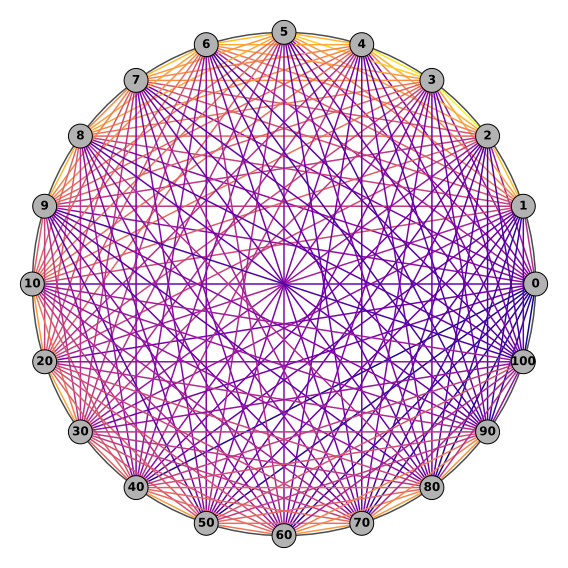

In [10]:
# values for theta
N = len(tokens)
th = np.linspace(0,2*np.pi-2*np.pi*(1/N),N)

maxcs = np.sort(csM[csM<.99])[-1]

# create a figure
plt.figure(figsize=(8,8))

thHighres = np.linspace(0,2*np.pi,100)
plt.plot(np.cos(thHighres),np.sin(thHighres),color=[.3,.3,.3])

# loop over tokens
for i in range(N):

  # plot the dot
  plt.plot(np.cos(th[i]),np.sin(th[i]),'ko',markerfacecolor=[.7,.7,.7],markersize=24)

  # draw text at the tokens
  plt.text(np.cos(th[i]),np.sin(th[i]),tokenizer.decode([tokens[i]]),
           ha='center',va='center',fontweight='bold',fontsize=12,color='k')

  # loop over all the other tokens
  for j in range(i+1,N):

    # color corresponding to cossim strength
    cidx = (csM[i,j]-csM.min()) / (maxcs-csM.min())
    color = plt.cm.plasma(cidx)

    # draw it!
    x_vals = [ np.cos(th[i]),np.cos(th[j]) ]
    y_vals = [ np.sin(th[i]),np.sin(th[j]) ]
    plt.plot(x_vals,y_vals,zorder=-10,color=color)

plt.axis('off')

plt.tight_layout()
plt.savefig('ch3_proj11_part3.png')
plt.show()

In [11]:
import pandas as pd

similarity_rows = []

N = len(tokens)

for i in range(N):
    for j in range(i + 1, N):

        similarity_rows.append({
            'Token 1': tokenizer.decode([tokens[i]]),
            'Token 2': tokenizer.decode([tokens[j]]),
            'Index 1': tokens[i],
            'Index 2': tokens[j],
            'Cosine similarity': csM[i, j].item()
        })

similarity_table = (
    pd.DataFrame(similarity_rows)
    .sort_values(
        'Cosine similarity',
        ascending=False
    )
    .reset_index(drop=True)
)

display(similarity_table)

,Token 1,Token 2,Index 1,Index 2,Cosine similarity
0,2,3,1016,1017,0.820116
1,3,4,1017,1018,0.797096
2,3,5,1017,1019,0.763858
3,1,2,1015,1016,0.744802
4,5,6,1019,1020,0.744006
...,...,...,...,...,...
185,0,90,1014,3938,0.315174
186,0,50,1014,2753,0.307833
187,0,40,1014,2871,0.299203
188,0,80,1014,3770,0.292397


In [13]:
top_20 = similarity_table.tail(20)

display(
    top_20.style
    .background_gradient(
        subset=['Cosine similarity'],
        cmap='plasma'
    )
    .format({
        'Cosine similarity': '{:.4f}'
    })
)

,Token 1,Token 2,Index 1,Index 2,Cosine similarity
170,2,70,1016,3963,0.3660
171,2,80,1016,3770,0.3655
172,4,90,1018,3938,0.3652
173,2,100,1016,2531,0.3633
174,9,50,1023,2753,0.3630
175,1,60,1015,3438,0.3587
176,5,90,1019,3938,0.3559
177,2,90,1016,3938,0.3548
178,9,100,1023,2531,0.3523
179,6,90,1020,3938,0.3478


In [18]:
import pandas as pd

connection_rows = []

N = len(tokens)

for i in range(N):
    for j in range(i + 1, N):

        similarity = csM[i, j].item()

        if similarity > thresh:

            connection_rows.append({
                'Token 1': repr(
                    tokenizer.decode([tokens[i]])
                ),
                'Token 2': repr(
                    tokenizer.decode([tokens[j]])
                ),
                'Token index 1': tokens[i],
                'Token index 2': tokens[j],
                'Cosine similarity': similarity
            })

word_connections = (
    pd.DataFrame(connection_rows)
    .sort_values(
        'Cosine similarity',
        ascending=False
    )
    .reset_index(drop=True)
)

display(
    word_connections.style
    .background_gradient(
        subset=['Cosine similarity'],
        cmap='plasma'
    )
    .format({
        'Cosine similarity': '{:.4f}'
    })
)

,Token 1,Token 2,Token index 1,Token index 2,Cosine similarity
0,'2','3',1016,1017,0.8201
1,'3','4',1017,1018,0.7971
2,'3','5',1017,1019,0.7639
3,'1','2',1015,1016,0.7448
4,'5','6',1019,1020,0.7440
5,'6','7',1020,1021,0.7412
6,'8','9',1022,1023,0.7320
7,'4','5',1018,1019,0.7317
8,'2','4',1016,1018,0.7242
9,'5','8',1019,1022,0.7176
